# Prior sensitivity of the Bayesian results

The paper uses one prior for every example: spike-and-slab with spike weight $\pi = 0.75$ (prior probability that a
candidate reaction is absent) and a Gamma slab with shape $\alpha = 2$ and rate $\beta = 0.25$ (prior mean 8, sd 5.7).
This notebook reruns the inference with other priors and measures how much the results change.

**Cases** (the data-poor settings, where the prior matters most):
* ergodic example (antithetic integral controller), $T = 100$;
* predator–prey, $T = 40$;
* random network, $T = 100$.

**Priors** (each changes one thing relative to the baseline):

| name | $\pi$ | slab | slab mean (sd) |
|---|---|---|---|
| baseline | 0.75 | Gamma(2, rate 0.25) | 8 (5.7) |
| pi = 0.5 | 0.50 | Gamma(2, rate 0.25) | 8 (5.7) |
| pi = 0.9 | 0.90 | Gamma(2, rate 0.25) | 8 (5.7) |
| flat slab | 0.75 | Gamma(1, rate 0.1) | 10 (10) |
| tight slab | 0.75 | Gamma(2, rate 1) | 2 (1.4) |

The tight slab puts little prior mass on large rates (e.g. $\mu = 6$ in the ergodic example), so it is a demanding test.

Everything else is as in the paper (`run_channel_mcmc`: 500,000 iterations, burn-in 50,000, thinning 100, the same seeds
as the paper for every prior, so differences between priors are not Monte Carlo noise from different random numbers).
The baseline run reproduces the paper's saved results, which is checked below.

**What is compared**, for each case and prior against the baseline:
* active reactions: largest change of a posterior mean (relative to the true rate), largest relative change of a 95%
  interval width, and how many intervals contain the true rate;
* inactive reactions: the smallest $\Pr(\text{off})$; active reactions: the largest $\Pr(\text{off})$;
* how many reactions change classification (present if $\Pr(\text{off}) < 0.5$).

A remark on $\Pr(\text{off})$: the posterior odds of "absent" equal the prior odds $\pi/(1-\pi)$ times the Bayes factor
from the data, so when the data are weak, $\Pr(\text{off})$ moves with $\pi$ by construction. What matters is whether
it moves enough to change a conclusion.

**Modes:** `RUN_MCMC = True` runs all 15 combinations (about 30–40 minutes on two cores); a combination that has
finished (file `done.txt` in its folder) is skipped, so an interrupted run can be resumed;
`RUN_MCMC = False` only reads the saved results in `results/prior_sensitivity/`.

**Outputs:** `results/prior_sensitivity/` (one folder per case and prior, plus `all_results.csv`),
`writing/table_prior_sensitivity.tex`, `writing/fig_prior_sensitivity.pdf`.

In [1]:
import sys, os, io, contextlib, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath(".."))
warnings.filterwarnings("ignore", category=RuntimeWarning)   # 0/0 in diagnostics of switched-off reactions
with contextlib.redirect_stdout(io.StringIO()):
    from src.parsing import *
    from src.inference import *
    from src.mcmc import *

RUN_MCMC = False          # True: rerun all cases and priors (30-40 minutes); False: read saved results
N_JOBS   = 2              # parallel jobs (one per case and prior)

OUT = "../results/prior_sensitivity"
CASES = {   # name: (network file, trajectory file, seed used in the paper, saved paper results)
    "ergodic, T=100":        ("../data/example6_network.json", "../data/example6_T100_trajectory.json", 6, "../results/example6_T100"),
    "predator-prey, T=40":   ("../data/example4_network.json", "../data/example4_T40_trajectory.json",  4, "../results/example4_T40"),
    "random network, T=100": ("../data/example5_network.json", "../data/example5_T100_trajectory.json", 5, "../results/example5_T100"),
}
PRIORS = {  # name: (pi, alpha, beta)
    "baseline":   (0.75, 2, 0.25),
    "pi = 0.5":   (0.50, 2, 0.25),
    "pi = 0.9":   (0.90, 2, 0.25),
    "flat slab":  (0.75, 1, 0.10),
    "tight slab": (0.75, 2, 1.00),
}
slug = lambda s: s.replace(", ", "_").replace(" = ", "").replace(" ", "_").replace("=", "")


### Run the MCMC for every case and prior

In [2]:
def run_case(case, prior):
    """All observed channels of one case under one prior; writes OUT/<case>/<prior>/mcmc_summary.xlsx."""
    net_file, traj_file, seed, _ = CASES[case]
    pi, alpha, beta = PRIORS[prior]
    out_dir = os.path.join(OUT, slug(case), slug(prior))
    if os.path.exists(os.path.join(out_dir, "done.txt")):      # finished in an earlier run: skip (delete to rerun)
        return case, prior, 0.0
    os.makedirs(out_dir, exist_ok=True)
    sf = os.path.join(out_dir, "mcmc_summary.xlsx")
    if os.path.exists(sf):
        os.remove(sf)
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        (_, _, _, _, trueTheta, _, _, reactant_matrix, unique_changes, compatible_reactions, _) = load_reaction_network(net_file)
        tl, sl = load_trajectory(traj_file)
        _, jc, wt, pr = parse_trajectory(sl, tl, reactant_matrix, unique_changes, compatible_reactions, verbose=False)
        for index, dX in enumerate(unique_changes):
            lc, lw, lp, sel = extract_local_data(jc, wt, pr, unique_changes, index=index, deltaX=dX, verbose=False)
            n = sum(lc.values())
            if n == 0:
                continue
            run_channel_mcmc(lc, lw, lp, trueTheta[compatible_reactions[sel]], trueTheta, results_dir=out_dir,
                             index=index, total_count=n, seed=seed, alpha=alpha, beta=beta, pi=pi, make_plots=False)
    open(os.path.join(out_dir, "done.txt"), "w").write(f"{time.time() - t0:.0f} s\n")
    return case, prior, time.time() - t0

if RUN_MCMC:
    from joblib import Parallel, delayed
    jobs = [(c, p) for c in CASES for p in PRIORS]
    t0 = time.time()
    done = Parallel(n_jobs=N_JOBS)(delayed(run_case)(c, p) for c, p in jobs)
    for c, p, s in done:
        print(f"{c:24s} {p:12s} {s/60:5.1f} min")
    print(f"total wall time {(time.time() - t0)/60:.1f} min")


### Collect the results

In [3]:
rows = []
for case in CASES:
    for prior in PRIORS:
        d = pd.read_excel(os.path.join(OUT, slug(case), slug(prior), "mcmc_summary.xlsx"))
        d["case"], d["prior"] = case, prior
        rows.append(d)
res = pd.concat(rows, ignore_index=True)
res["active"] = res["True_Theta"] > 0
res["width"] = res["CI_upper"] - res["CI_lower"]
res["covers"] = (res["CI_lower"] <= res["True_Theta"]) & (res["True_Theta"] <= res["CI_upper"])
res["present"] = res["Prob_Off"] < 0.5
res.to_csv(os.path.join(OUT, "all_results.csv"), index=False)
key = ["case", "Run_Index", "Param_Index"]

# the baseline rerun must reproduce the paper's saved results
for case, (_, _, _, saved_dir) in CASES.items():
    s = pd.read_excel(os.path.join(saved_dir, "mcmc_summary.xlsx"))
    b = res[(res.case == case) & (res.prior == "baseline")]
    m = b.merge(s, on=["Run_Index", "Param_Index"], suffixes=("", "_paper"))
    print(f"{case:24s} baseline vs paper: {len(m)} rates, max |difference in posterior mean| = "
          f"{np.abs(m['Mean'] - m['Mean_paper']).max():.1e}")


ergodic, T=100           baseline vs paper: 17 rates, max |difference in posterior mean| = 0.0e+00
predator-prey, T=40      baseline vs paper: 12 rates, max |difference in posterior mean| = 0.0e+00
random network, T=100    baseline vs paper: 51 rates, max |difference in posterior mean| = 0.0e+00


### Summary: change relative to the baseline prior

In [4]:
base = res[res.prior == "baseline"].set_index(key)
summ = []
for (case, prior), g in res.groupby(["case", "prior"], sort=False):
    g = g.set_index(key)
    b = base.loc[g.index]
    a = g["active"]
    summ.append({
        "case": case, "prior": prior,
        "max |change of mean| (% of true rate)": 100 * (np.abs(g.Mean - b.Mean)[a] / g.True_Theta[a]).max(),
        "max |change of CI width| (%)": 100 * (np.abs(g.width - b.width)[a] / b.width[a]).max(),
        "CIs covering truth": f"{int(g.covers[a].sum())}/{int(a.sum())}",
        "min Pr(off), inactive": g.Prob_Off[~a].min(),
        "max Pr(off), active": g.Prob_Off[a].max(),
        "classification changes": int((g.present != b.present).sum()),
        "min ESS, active": g.ESS[a].min(),
    })
summ = pd.DataFrame(summ)
pd.set_option("display.width", 200)
print(summ.round(3).to_string(index=False))


                 case      prior  max |change of mean| (% of true rate)  max |change of CI width| (%) CIs covering truth  min Pr(off), inactive  max Pr(off), active  classification changes  min ESS, active
       ergodic, T=100   baseline                                  0.000                         0.000                6/6                  0.994                0.000                       0         3984.786
       ergodic, T=100   pi = 0.5                                  1.409                        42.767                6/6                  0.957                0.000                       0         1217.000
       ergodic, T=100   pi = 0.9                                  0.129                         3.892                6/6                  0.994                0.000                       0         3477.159
       ergodic, T=100  flat slab                                  3.849                        70.984                6/6                  0.878                0.000            

### Active rates under each prior

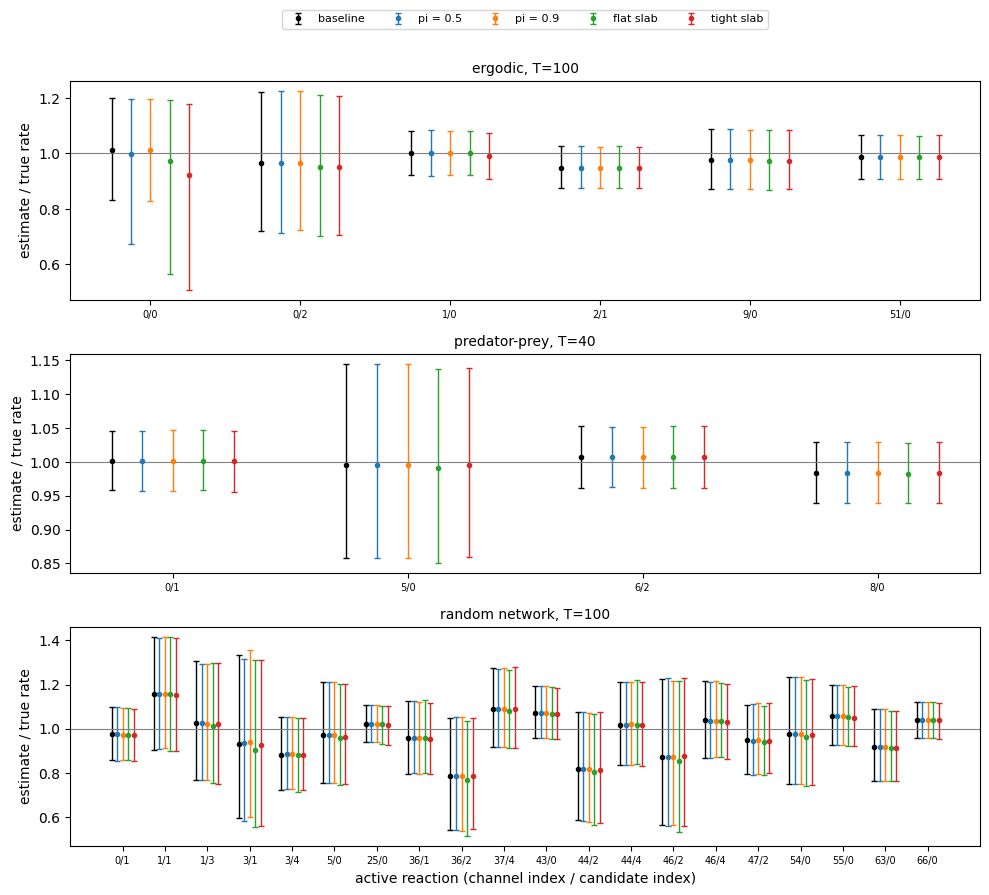

In [5]:
act = res[res.active].copy()
act["label"] = act["Run_Index"].astype(str) + "/" + act["Param_Index"].astype(str)
colors = dict(zip(PRIORS, ["k", "tab:blue", "tab:orange", "tab:green", "tab:red"]))
fig, axes = plt.subplots(len(CASES), 1, figsize=(10, 3.0 * len(CASES)))
for ax, case in zip(axes, CASES):
    g = act[act.case == case]
    labels = list(dict.fromkeys(g.label))
    for j, prior in enumerate(PRIORS):
        h = g[g.prior == prior].set_index("label").loc[labels]
        x = np.arange(len(labels)) + (j - 2) * 0.13
        ax.errorbar(x, h.Mean / h.True_Theta,
                    yerr=[(h.Mean - h.CI_lower) / h.True_Theta, (h.CI_upper - h.Mean) / h.True_Theta],
                    fmt="o", ms=3, color=colors[prior], label=prior, capsize=2, lw=1)
    ax.axhline(1, color="gray", lw=0.8)
    ax.set_xticks(np.arange(len(labels))); ax.set_xticklabels(labels, fontsize=7)
    ax.set_title(case, fontsize=10); ax.set_ylabel("estimate / true rate")
axes[0].legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.35))
axes[-1].set_xlabel("active reaction (channel index / candidate index)")
plt.tight_layout()
plt.savefig("../writing/fig_prior_sensitivity.pdf", bbox_inches="tight")
plt.savefig(os.path.join(OUT, "fig_prior_sensitivity.png"), dpi=120, bbox_inches="tight")
plt.show()


### LaTeX table

In [6]:
L = [r"% Prior sensitivity -- generated by examples/prior_sensitivity.ipynb -- do not edit by hand",
     r"\begin{table}[htbp]", r"\centering", r"\footnotesize", r"\setlength{\tabcolsep}{3pt}",
     r"\caption{Prior sensitivity. Each prior changes one setting of the baseline prior used in the paper "
     r"($\pi = 0.75$, Gamma slab with shape 2 and rate 0.25). For the active reactions: the largest change of a posterior "
     r"mean, relative to the true rate, and of a 95\% interval width, relative to the baseline, and the number of "
     r"intervals that contain the true rate; smallest $\Pr(\text{off})$ over the inactive and largest over the active "
     r"candidate reactions; number of reactions whose classification (present if $\Pr(\text{off})<0.5$) differs from the "
     r"baseline.}",
     r"\label{tab:prior_sensitivity}",
     r"\begin{tabular}{l l r r c r r c}", r"\toprule",
     r"case & prior & $\max|\Delta\,\text{mean}|$ & $\max|\Delta\,\text{width}|$ & coverage & "
     r"\multicolumn{2}{c}{$\Pr(\text{off})$} & changes \\",
     r"\cmidrule(lr){6-7}",
     r" & & (\% of $k^*$) & (\%) & & min, inactive & max, active & \\", r"\midrule"]
for case in CASES:
    g = summ[summ.case == case]
    for j, (_, r) in enumerate(g.iterrows()):
        L.append((case if j == 0 else "") + f" & {r.prior} & {r['max |change of mean| (% of true rate)']:.1f} & "
                 f"{r['max |change of CI width| (%)']:.1f} & {r['CIs covering truth']} & {r['min Pr(off), inactive']:.3f} & "
                 f"{r['max Pr(off), active']:.3f} & {r['classification changes']} \\\\")
    L.append(r"\midrule")
L[-1] = r"\bottomrule"
L += [r"\end{tabular}", r"\end{table}"]
open("../writing/table_prior_sensitivity.tex", "w").write("\n".join(L) + "\n")
print("\n".join(L))


% Prior sensitivity -- generated by examples/prior_sensitivity.ipynb -- do not edit by hand
\begin{table}[htbp]
\centering
\footnotesize
\setlength{\tabcolsep}{3pt}
\caption{Prior sensitivity. Each prior changes one setting of the baseline prior used in the paper ($\pi = 0.75$, Gamma slab with shape 2 and rate 0.25). For the active reactions: the largest change of a posterior mean, relative to the true rate, and of a 95\% interval width, relative to the baseline, and the number of intervals that contain the true rate; smallest $\Pr(\text{off})$ over the inactive and largest over the active candidate reactions; number of reactions whose classification (present if $\Pr(\text{off})<0.5$) differs from the baseline.}
\label{tab:prior_sensitivity}
\begin{tabular}{l l r r c r r c}
\toprule
case & prior & $\max|\Delta\,\text{mean}|$ & $\max|\Delta\,\text{width}|$ & coverage & \multicolumn{2}{c}{$\Pr(\text{off})$} & changes \\
\cmidrule(lr){6-7}
 & & (\% of $k^*$) & (\%) & & min, inactive & max